# Exploratory data analysis: MIT-BIH beats (DS1)

What the data looks like before modelling: class balance, differences between patients, beat shapes, RR intervals, preprocessing and noise.

Only DS1 is used here (the 22 training and validation records). DS2, the test records, is kept untouched for the final evaluation. The beats, windows and RR intervals are built with the same functions in `src/dataset.py` that the models use: lead MLII, 100-sample windows (278 ms at 360 Hz) centred on the annotated R-peak, band-pass and notch filtering, and the AAMI classes N, S, V and F.

In [1]:
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import wfdb

sys.path.insert(0, os.path.abspath(os.path.join("..", "src")))
import dataset

window_size, offset = 100, 0
CLASSES = ["N", "S", "V", "F"]
CLASS_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
SPLIT_COLORS = {"train": "#6250d6", "val": "#e87ba4"}
INK, SECONDARY, MUTED, SURFACE = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"
NOISE_DIR = dataset.noise_directory
pd.set_option("display.width", 140)


def style(ax, title=None):
    ax.set_facecolor(SURFACE)
    ax.grid(axis="y", color="#e5e4e0", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=SECONDARY, labelsize=9)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_color(MUTED)
    if title:
        ax.set_title(title, loc="left", fontsize=10, color=INK)

In [2]:
rows, windows, signals = [], [], {}
for split, records in [("train", dataset.train_records), ("val", dataset.val_records)]:
    for record_name in records:
        record = wfdb.rdrecord(dataset.directory + record_name)
        annotation = wfdb.rdann(dataset.directory + record_name, "atr")
        signal = record.p_signal[:, 0]
        signals[record_name] = (signal, annotation, record.fs)
        beat_samples, labels = dataset.kept_beats(annotation, len(signal), window_size, offset)
        rr = dataset.rr_intervals(beat_samples, dataset.annotated_peaks(annotation), record.fs)
        windows.append(dataset.beat_windows(dataset.filter_signal(signal, record.fs), beat_samples, window_size, offset))
        rows += [(split, record_name, CLASSES[label], pre, post)
                 for label, (pre, post) in zip(labels, rr)]

beats = pd.DataFrame(rows, columns=["split", "record", "label", "pre_rr", "post_rr"])
windows = np.concatenate(windows)
print(f"{len(beats):,} beats from {beats['record'].nunique()} records")

51,009 beats from 22 records


## 1. Class balance

label,N,S,V,F
split,,,,
train,37075,738,3046,387
val,8788,206,742,27


label,N (%),S (%),V (%),F (%)
split,,,,
train,89.89,1.79,7.38,0.94
val,90.01,2.11,7.60,0.28


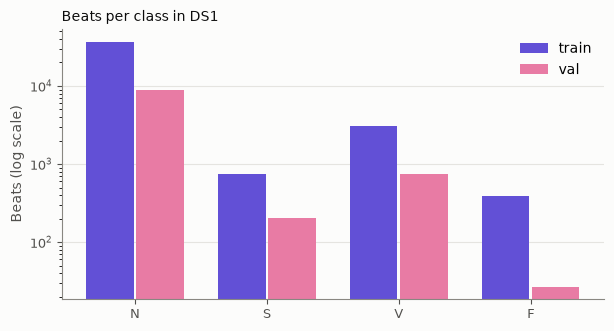

In [3]:
counts = beats.groupby(["split", "label"]).size().unstack(fill_value=0)[CLASSES]
display(counts)
display((counts.div(counts.sum(axis=1), axis=0) * 100).round(2).add_suffix(" (%)"))

fig, ax = plt.subplots(figsize=(7, 3.5), facecolor=SURFACE)
x = np.arange(len(CLASSES))
for i, split in enumerate(["train", "val"]):
    ax.bar(x + (i - 0.5) * 0.38, counts.loc[split], width=0.36, color=SPLIT_COLORS[split], label=split)
ax.set_yscale("log")
ax.set_xticks(x, CLASSES)
ax.set_ylabel("Beats (log scale)", color=SECONDARY)
ax.legend(frameon=False)
style(ax, "Beats per class in DS1")
plt.show()

## 2. Differences between patients

Each record is one patient. The table shows how the classes are spread over the records.

In [4]:
per_record = beats.groupby(["split", "record", "label"]).size().unstack(fill_value=0)[CLASSES]
per_record["total"] = per_record.sum(axis=1)
per_record["non-N (%)"] = ((per_record["total"] - per_record["N"]) / per_record["total"] * 100).round(1)
display(per_record)

for cls in ["S", "V", "F"]:
    top = per_record[cls].sort_values(ascending=False)
    share = top.head(3).sum() / top.sum() * 100
    print(f"{cls}: {top.sum():,} beats, {(top > 0).sum()} of {len(top)} records have any, "
          f"the top 3 records hold {share:.0f} % ({', '.join(r for _, r in top.head(3).index)})")

label            N    S    V    F  total  non-N (%)
split record                                       
train 101     1860    3    0    0   1863        0.2
      106     1507    0  520    0   2027       25.7
      108     1740    4   17    2   1763        1.3
      109     2492    0   38    2   2532        1.6
      114     1820   12   43    4   1879        3.1
      115     1952    0    0    0   1952        0.0
      116     2301    1  109    0   2411        4.6
      118     2166   96   16    0   2278        4.9
      119     1543    0  444    0   1987       22.3
      122     2476    0    0    0   2476        0.0
      124     1536   31   47    5   1619        5.1
      203     2529    2  444    1   2976       15.0
      207     1543  107  210    0   1860       17.0
      208     1586    2  992  372   2952       46.3
      209     2621  383    1    0   3005       12.8
      215     3195    3  164    1   3363        5.0
      220     1953   94    0    0   2047        4.6
      230     2255    0    1    0   2256        0.0
val   112     2537    2    0    0   2539        0.1
      201     1635  128  198    2   1963       16.7
      205     2571    3   71   11   2656        3.2
      223     2045   73  473   14   2605       21.5

S: 944 beats, 16 of 22 records have any, the top 3 records hold 65 % (209, 201, 207)
V: 3,788 beats, 17 of 22 records have any, the top 3 records hold 52 % (208, 106, 223)
F: 414 beats, 10 of 22 records have any, the top 3 records hold 96 % (208, 223, 205)


## 3. Beat shapes per class

Average window per class in the training data (line) with ± one standard deviation (band). Each window is z-normalized on its own, as in the model input.

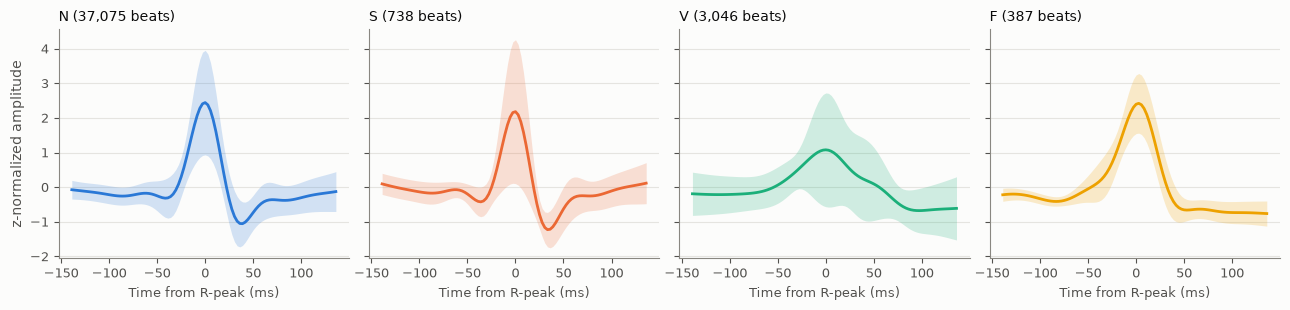

In [5]:
train = (beats["split"] == "train").to_numpy()
time_ms = (np.arange(window_size) - window_size // 2 + offset) / 360 * 1000

fig, axes = plt.subplots(1, 4, figsize=(13, 3.2), sharey=True, facecolor=SURFACE)
for ax, cls, color in zip(axes, CLASSES, CLASS_COLORS):
    selected = windows[train & (beats["label"] == cls).to_numpy()]
    mean, std = selected.mean(axis=0), selected.std(axis=0)
    ax.fill_between(time_ms, mean - std, mean + std, color=color, alpha=0.2, linewidth=0)
    ax.plot(time_ms, mean, color=color, linewidth=2)
    ax.set_xlabel("Time from R-peak (ms)", color=SECONDARY, fontsize=9)
    style(ax, f"{cls} ({len(selected):,} beats)")
axes[0].set_ylabel("z-normalized amplitude", color=SECONDARY)
plt.tight_layout()
plt.show()

## 4. RR intervals per class

`pre_rr` is the time from the previous beat and `post_rr` the time to the next beat, in the training data.

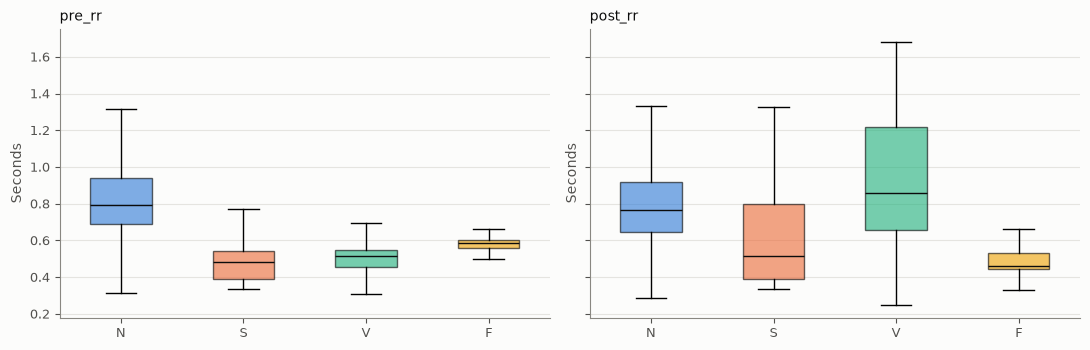

,pre_rr,post_rr,post / pre
label,,,
N,0.794,0.767,0.97
S,0.481,0.514,1.07
V,0.514,0.858,1.67
F,0.583,0.461,0.79


In [6]:
train_beats = beats[beats["split"] == "train"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True, facecolor=SURFACE)
for ax, column in zip(axes, ["pre_rr", "post_rr"]):
    data = [train_beats.loc[train_beats["label"] == cls, column] for cls in CLASSES]
    parts = ax.boxplot(data, tick_labels=CLASSES, showfliers=False, patch_artist=True, widths=0.5,
                       medianprops={"color": INK})
    for box, color in zip(parts["boxes"], CLASS_COLORS):
        box.set_facecolor(color)
        box.set_alpha(0.6)
    ax.set_ylabel("Seconds", color=SECONDARY)
    style(ax, column)
plt.tight_layout()
plt.show()

summary = train_beats.groupby("label")[["pre_rr", "post_rr"]].median().loc[CLASSES]
summary["post / pre"] = (summary["post_rr"] / summary["pre_rr"]).round(2)
display(summary.round(3))

## 5. Preprocessing

Five seconds of record 106 before and after the band-pass (0.5–20 Hz) and notch filter. The letters are the annotated beat classes.

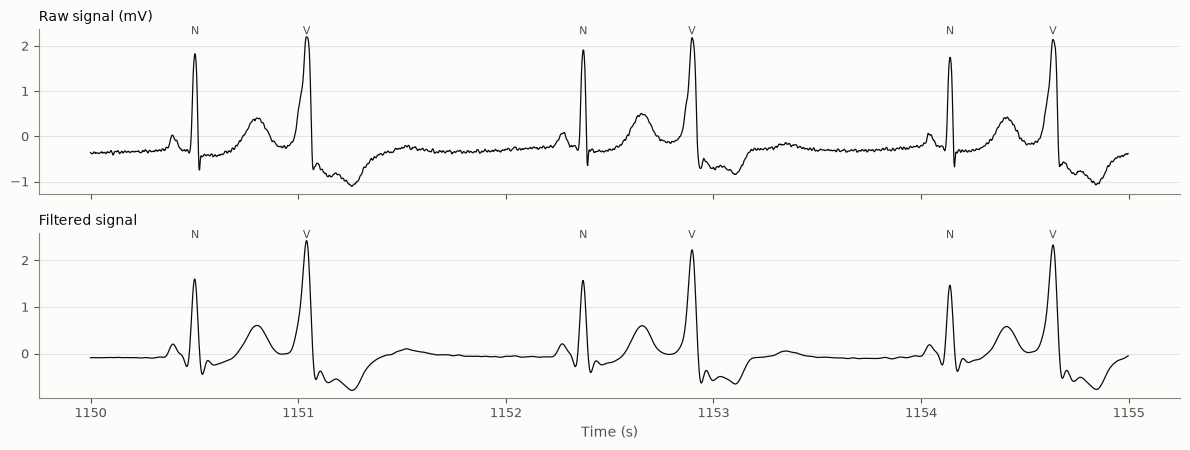

In [7]:
def show_segment(ax, record_name, signal, start_s, seconds, title, color=INK):
    _, annotation, fs = signals[record_name]
    start, end = int(start_s * fs), int((start_s + seconds) * fs)
    time = np.arange(start, end) / fs
    ax.plot(time, signal[start:end], color=color, linewidth=0.9)
    top = signal[start:end].max()
    for sample, symbol in zip(annotation.sample, annotation.symbol):
        if start <= sample < end and symbol in dataset.AAMI_MAPPING:
            ax.text(sample / fs, top, CLASSES[dataset.AAMI_MAPPING[symbol]], ha="center", va="bottom",
                    fontsize=8, color=SECONDARY)
    style(ax, title)


raw, _, fs = signals["106"]
fig, axes = plt.subplots(2, 1, figsize=(12, 4.6), sharex=True, facecolor=SURFACE)
show_segment(axes[0], "106", raw, 1150, 5, "Raw signal (mV)")
show_segment(axes[1], "106", dataset.filter_signal(raw, fs), 1150, 5, "Filtered signal")
axes[1].set_xlabel("Time (s)", color=SECONDARY)
plt.tight_layout()
plt.show()

## 6. Noise from the Noise Stress Test Database

The same five seconds with each noise type added at 0 dB, the strongest level in the noise test (signal and noise have equal power), after filtering.

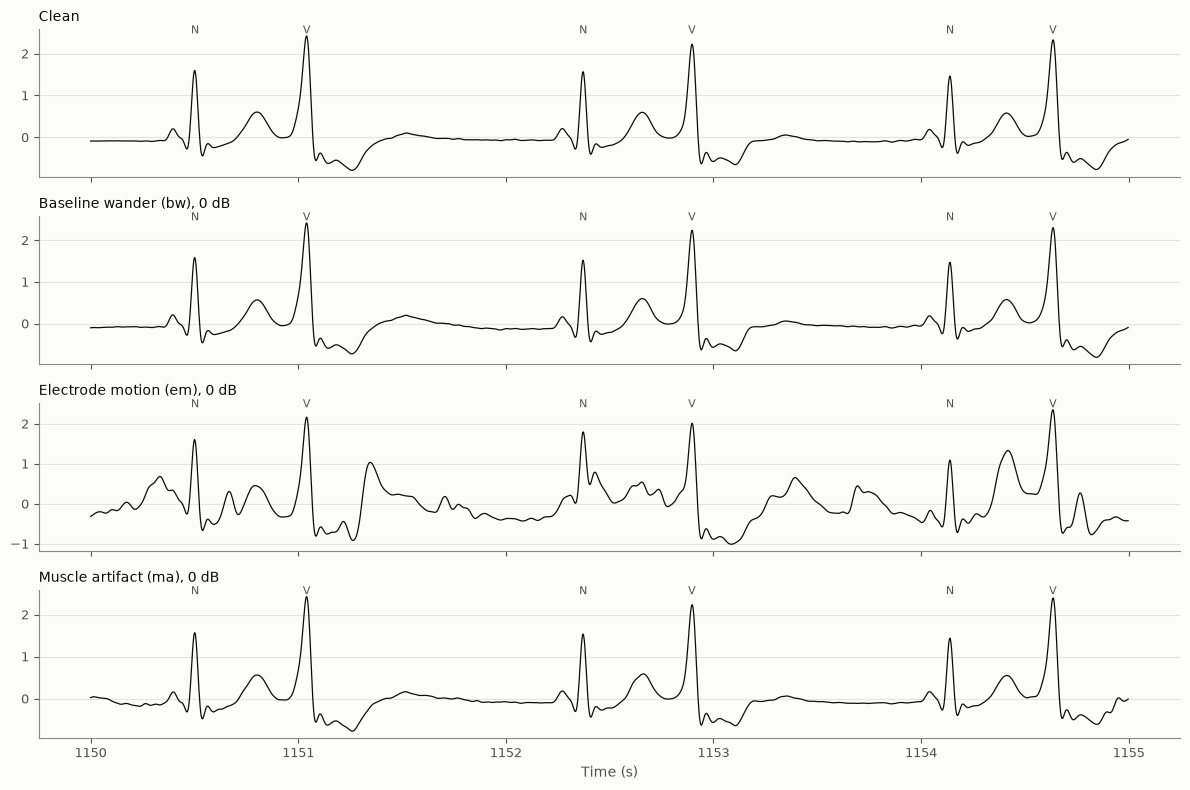

In [8]:
noise_names = {"bw": "Baseline wander (bw)", "em": "Electrode motion (em)", "ma": "Muscle artifact (ma)"}
fig, axes = plt.subplots(4, 1, figsize=(12, 8), sharex=True, facecolor=SURFACE)
show_segment(axes[0], "106", dataset.filter_signal(raw, fs), 1150, 5, "Clean")
for ax, (name, title) in zip(axes[1:], noise_names.items()):
    noise = wfdb.rdrecord(NOISE_DIR + name).p_signal[:, 0]
    noisy = dataset.filter_signal(dataset.add_noise(raw, noise, 0), fs)
    show_segment(ax, "106", noisy, 1150, 5, f"{title}, 0 dB")
axes[-1].set_xlabel("Time (s)", color=SECONDARY)
plt.tight_layout()
plt.show()

## Summary

- **Strong class imbalance.** About 90 % of the DS1 beats are N. S is about 2 %, V about 7.5 % and F under 1 % (0.94 % in training, 27 beats or 0.28 % in validation). This is why the models use a weighted sampler or class weights, and why macro F1 is the main metric instead of accuracy.
- **The rare classes come from few patients.** 96 % of the F beats come from three records, and record 208 alone holds 372 of the 414. The model therefore learns F almost entirely from one patient, which helps explain why F is hardly recognized on new patients. S is also concentrated (65 % in three records). A split by record, as used here, is needed to measure how well the model generalizes to new patients.
- **S looks like N.** The average S beat has the same narrow QRS shape as N, so the shape of the window alone cannot separate them well. V beats are wider and vary much more between patients (wide band, and in some records the QRS is inverted). F lies between N and V.
- **Timing separates the classes.** S and V come early (median `pre_rr` about 0.48 and 0.51 s against 0.79 s for N). V is followed by a compensatory pause (median `post_rr` / `pre_rr` 1.67). This motivated adding RR as input channels to the CNN, which raised validation macro F1 from 43 % to about 50 %.
- **Filtering removes much of the noise.** The 0.5–20 Hz band-pass removes baseline wander almost completely and much of the muscle artifact. Electrode motion at 0 dB leaves beat-like bumps inside the pass band, which is why it is the hardest noise type in the noise test.